# SGD, Momentum, RMSprop, Adam, AdamW, and Loss Landscapes

**AI Mathematics · 5. Optimization**

Compare practical first-order optimizers and understand how loss geometry can complicate deep-network training.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Implement basic SGD, momentum, RMSprop, Adam, and decoupled weight decay.
- Explain vanishing and exploding gradients.
- Interpret saddle points and sharp versus flat minima carefully.

In [1]:
import numpy as np

## 1. SGD and momentum
SGD subtracts a gradient-scaled step. Momentum accumulates a moving average of gradients and can reduce oscillation in narrow valleys. The exact update convention varies by library; be explicit about the formula used.

In [2]:
import numpy as np

gradients = [np.array([2.0, -1.0]), np.array([1.0, -0.5]), np.array([0.5, -0.25])]
lr, beta = 0.1, 0.9
v = np.zeros(2)
for g in gradients:
    v = beta*v + g
    step = -lr*v
    print("momentum step:", step)

momentum step: [-0.2  0.1]
momentum step: [-0.28  0.14]
momentum step: [-0.302  0.151]


## 2. RMSprop and Adam
RMSprop tracks a moving average of squared gradients to scale parameter-wise steps. Adam tracks both first and second moments and uses bias corrections. Adaptive scaling helps across different gradient magnitudes but does not guarantee better generalization or convergence for every problem.

In [3]:
g = np.array([2.0, -0.5])
beta1, beta2, eps = 0.9, 0.999, 1e-8
m = np.zeros_like(g); v = np.zeros_like(g)
t = 1
m = beta1*m + (1-beta1)*g
v = beta2*v + (1-beta2)*(g*g)
m_hat = m / (1-beta1**t)
v_hat = v / (1-beta2**t)
step = 0.01 * m_hat / (np.sqrt(v_hat) + eps)
print("Adam parameter step:", step)

Adam parameter step: [ 0.01 -0.01]


## 3. AdamW and weight decay
AdamW applies weight decay separately from the adaptive gradient update. This differs from simply adding an L2 penalty to the loss under adaptive optimization. Weight decay changes parameter magnitudes directly; tune it separately from the learning rate.

In [4]:
w = np.array([2.0, -1.0])
g = np.array([0.5, -0.25])
lr, weight_decay = 0.01, 0.1
# Illustrative decoupled AdamW-style update using an already-preconditioned direction.
adaptive_direction = np.array([0.8, -0.4])
w_new = w - lr*adaptive_direction - lr*weight_decay*w
print("updated parameters:", w_new)

updated parameters: [ 1.99  -0.995]


## 4. Vanishing and exploding gradients
In deep compositions, repeated multiplication by Jacobians can shrink gradients toward zero or amplify them dramatically. Vanishing gradients hinder learning in early layers; exploding gradients cause unstable updates. Initialization, normalization, residual connections, activation choice, and gradient clipping are common mitigations.

In [5]:
# Simplified scalar chain: gradient is a product of local derivatives
for factor in [0.5, 1.0, 1.5]:
    grad = factor**30
    print("local derivative:", factor, "product across 30 layers:", grad)

local derivative: 0.5 product across 30 layers: 9.313225746154785e-10
local derivative: 1.0 product across 30 layers: 1.0
local derivative: 1.5 product across 30 layers: 191751.0592328841


## 5. Saddles and sharp/flat minima
A saddle has zero gradient but mixed curvature directions. In high dimensions, saddle-like regions can be important even when strict local minima are rare. “Sharp” and “flat” minima describe local loss geometry, but generalization claims depend on parameterization, scale, data, and the metric used; they should not be treated as universal guarantees.

In [6]:
H_minimum = np.diag([1.0, 3.0])
H_saddle = np.diag([2.0, -1.0])
print("minimum curvature eigenvalues:", np.linalg.eigvalsh(H_minimum))
print("saddle curvature eigenvalues:", np.linalg.eigvalsh(H_saddle))

# Sharp and flat quadratics centered at the same minimum.
H_sharp = np.diag([50.0, 100.0])
H_flat = np.diag([0.1, 0.2])
print("sharp curvature:", np.linalg.eigvalsh(H_sharp))
print("flat curvature:", np.linalg.eigvalsh(H_flat))

# Gradient clipping by global norm
g = np.array([30.0, 40.0])
max_norm = 5.0
norm = np.linalg.norm(g)
g_clipped = g * min(1.0, max_norm/norm)
print("original norm:", norm, "clipped norm:", np.linalg.norm(g_clipped))

minimum curvature eigenvalues: [1. 3.]
saddle curvature eigenvalues: [-1.  2.]
sharp curvature: [ 50. 100.]
flat curvature: [0.1 0.2]
original norm: 50.0 clipped norm: 5.0


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: compare optimizer updates on a toy objective

This is a transparent, one-parameter simulation, not a claim that one optimizer is universally best. Momentum accumulates a velocity; RMSprop rescales updates using recent squared gradients; Adam combines first- and second-moment estimates; AdamW applies weight decay separately from the adaptive gradient update. Implementation details differ across frameworks, so read a library's documentation before expecting bit-for-bit identical results.

17_sgd_momentum_rmsprop_adam_adamw.ipynb:cell15:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,method,parameter,loss
403,Adam,1.46634,0.00113
504,AdamW,1.42627,0.00544
201,Momentum,1.48300,0.00029
302,RMSprop,1.50000,0.00000
100,SGD,1.50000,0.00000


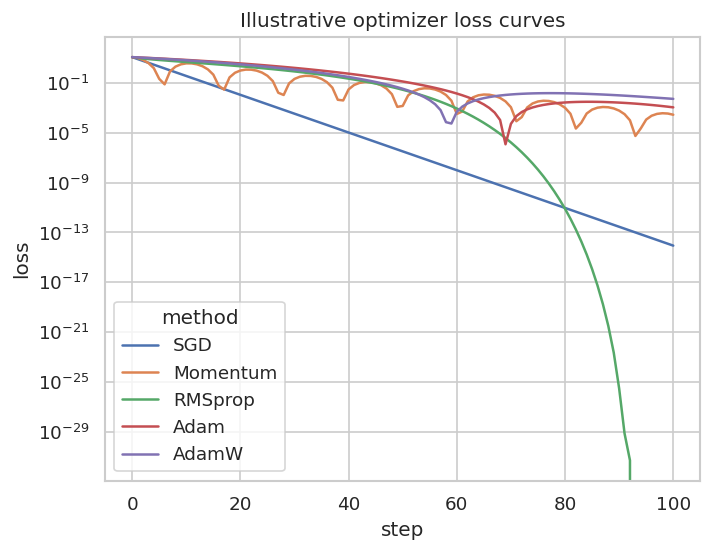

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_opt_methods = ["SGD", "Momentum", "RMSprop", "Adam", "AdamW"]
viz_opt_rows = []
for viz_method in viz_opt_methods:
    theta, velocity, sq_avg, m, v = 5.0, 0.0, 0.0, 0.0, 0.0
    for step in range(101):
        loss = (theta-1.5)**2
        viz_opt_rows.append({"method": viz_method, "step": step, "parameter": theta, "loss": loss})
        grad = 2*(theta-1.5)
        if viz_method == "SGD":
            theta -= 0.08*grad
        elif viz_method == "Momentum":
            velocity = 0.9*velocity + grad
            theta -= 0.04*velocity
        elif viz_method == "RMSprop":
            sq_avg = 0.9*sq_avg + 0.1*grad**2
            theta -= 0.08*grad/(np.sqrt(sq_avg)+1e-8)
        else:
            m = 0.9*m + 0.1*grad; v = 0.999*v + 0.001*grad**2
            m_hat = m/(1-0.9**(step+1)); v_hat = v/(1-0.999**(step+1))
            theta -= 0.08*m_hat/(np.sqrt(v_hat)+1e-8)
            if viz_method == "AdamW": theta -= 0.002*theta
viz_opt_df = pd.DataFrame(viz_opt_rows)
sns.lineplot(data=viz_opt_df, x="step", y="loss", hue="method")
plt.yscale("log"); plt.title("Illustrative optimizer loss curves"); plt.show()
display(viz_opt_df.groupby("method").tail(1)[["method", "parameter", "loss"]].sort_values("method").round(5))

### Vanishing and exploding gradient intuition

If gradients are repeatedly multiplied by factors below 1, their magnitude may shrink exponentially; factors above 1 can make them grow exponentially. Real networks involve matrix products, nonlinearities, normalization, and learned parameters, but this simple calculation illustrates why initialization and architecture matter.

17_sgd_momentum_rmsprop_adam_adamw.ipynb:cell17:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


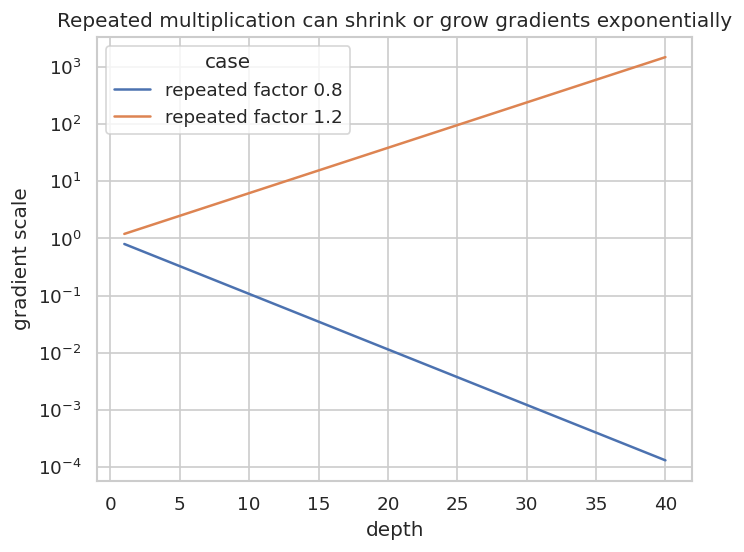

In [8]:
viz_depth = np.arange(1, 41)
viz_grad_scale_df = pd.DataFrame({"depth": viz_depth, "repeated factor 0.8": 0.8**viz_depth, "repeated factor 1.2": 1.2**viz_depth})
sns.lineplot(data=viz_grad_scale_df.melt(id_vars="depth", var_name="case", value_name="gradient scale"), x="depth", y="gradient scale", hue="case")
plt.yscale("log"); plt.title("Repeated multiplication can shrink or grow gradients exponentially"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Compute one momentum update with beta=0.8, v=0, g=[1,2].

In [9]:
v = 0.8*np.zeros(2) + np.array([1.0, 2.0])
print(v)

[1. 2.]


### Exercise 2
Exercise 2: Clip gradient [6,8] to global norm 2.

In [10]:
g = np.array([6.0, 8.0])
print(g * (2.0 / np.linalg.norm(g)))

[1.2 1.6]


## Key takeaways
- Optimizers differ in how they smooth or rescale gradients; no optimizer removes the need for tuning.
- Gradient products can vanish or explode in deep computation graphs.
- Loss-landscape descriptions are useful diagnostics, but sharpness and flatness require careful definitions.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.